# Analisis Segmentasi Spesies Penguin Menggunakan K-Means Clustering
---
## 1. Business Understanding

### 1.1 Latar Belakang, Masalah, Solusi
1. **Latar Belakang**: Sebuah pusat konservasi margasatwa dan peneliti biologi kelautan ingin membangun sistem kecerdasan buatan berbasis Unsupervised Machine Learning untuk mengelompokkan karakteristik fisik populasi penguin secara otomatis ke dalam beberapa klaster kelompok morfologi tanpa perlu melakukan identifikasi manual secara terus-menerus di lapangan.
2. **Masalah**: Pusat konservasi tersebut masih mengelompokkan karakteristik fisik populasi penguin secara manual yang memakan waktu dan tenaga kerja.
3. **Solusi**: Membangun model *machine learning* berbasis algoritma **K-Means** untuk mengelompokkan populasi penguin secara otomatis dengan memanfaatkan dataset yang merekam berbagai ukuran anatomi tubuh penguin yang dimiliki oleh pusat konservasi tersebut.

### 1.2 Deskripsi Kolom Dataset `penguins.csv`
| **Nama Kolom** | **Tipe Data** | **Keterangan** |
| :-- | :-- | :-- |
| `culmen_length_mm` | `float64` | Panjang paruh penguin (culmen length) (satuan: milimeter). |
| `culmen_depth_mm` | `float64` | Kedalaman paruh penguin (culmen depth) (satuan: milimeter). |
| `flipper_length_mm` | `float64` | Panjang sirip penguin (flipper length) (satuan: milimeter). |
| `body_mass_g` | `float64` | Berat badan penguin (satuan: gram). |
| `sex` | `str` | Jenis kelamin penguin (MALE / FEMALE). |

---
## 2. Data Preparation

### 2.1 Import Library

In [28]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load Dataset

In [29]:
df = pd.read_csv('penguins.csv', na_values=["NA", "NaN", ".", ""])
df.columns = df.columns.str.strip()

### 2.3 Tampilkan Data Teratas dan Data Terbawah

In [30]:
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [31]:
df.tail()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
339,NaN,NaN,NaN,NaN,NaN
340,46.8,14.3,215.0,4850.0,FEMALE
341,50.4,15.7,222.0,5750.0,MALE
342,45.2,14.8,212.0,5200.0,FEMALE
343,49.9,16.1,213.0,5400.0,MALE


### 2.4 Tampilkan Informasi Data

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                334 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


<a id="25-memeriksa-dimensi-data-jumlah-data-missing-value-dan-data-duplikat"></a>
<a id="25-memeriksa-dimensi-data-jumlah-data-missing-value-dan-data-dupliakt"></a>
### 2.5 Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Data Dupliakt

In [33]:
print(f'Dimensi Data: {df.shape}')
print(f'Jumlah Data: {df.size}')

print(f'\nJumlah Missing Value: {df.isnull().sum().sum()}')
print(f'---- Missing Value Pada Setiap olom ----\n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'\nData Duplikat: {df.duplicated().sum()}')

Dimensi Data: (344, 5)
Jumlah Data: 1720

Jumlah Missing Value: 18
---- Missing Value Pada Setiap olom ----
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

Data Duplikat: 1


---
## 3. Explaratory Data Analysis (EDA)

### 3.1 Tampilkan Deskripsi Data

In [34]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


### 3.2 Memeriksa Outlier dengan IQR dan Z-Score

In [35]:
outliers = []

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        median = df[col].median()
        mean = df[col].mean()
        std = df[col].std()
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z_score = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'standar deviasi': std,
            'min': df[col].min(),
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': df[col].max(),
            'batas bawah': lower,
            'batas atas': upper,
            'outlier (IQR)': outlier_iqr.shape[0],
            'outlier (Z-Score)': outlier_z_score.shape[0],
        })
        

pd.DataFrame(outliers)

,nama kolom,mean,standar deviasi,min,q1,median,q3,max,batas bawah,batas atas,outlier (IQR),outlier (Z-Score)
0,culmen_length_mm,43.921930,5.459584,32.1,39.225,44.45,48.50,59.6,25.3125,62.4125,0,0
1,culmen_depth_mm,17.151170,1.974793,13.1,15.600,17.30,18.70,21.5,10.9500,23.3500,0,0
2,flipper_length_mm,214.014620,260.558057,-132.0,190.000,197.00,213.75,5000.0,154.3750,249.3750,2,1
3,body_mass_g,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.00,6300.0,1750.0000,6550.0000,0,0


### 3.3 Visualisasi Outlier Dengan Bxplot

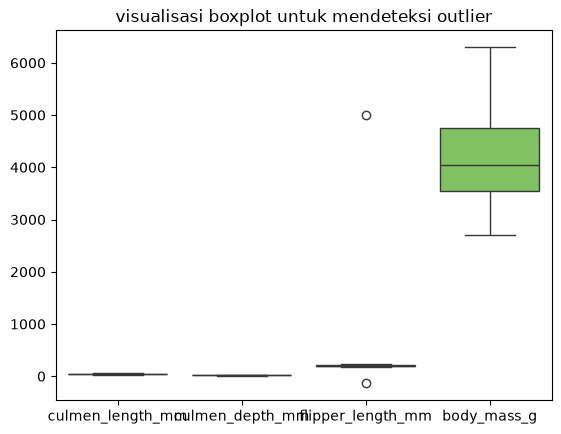

In [36]:
sns.boxplot(data=df[numeric_cols], palette='viridis')
plt.title('visualisasi boxplot untuk mendeteksi outlier')
plt.show()

### 3.4 Visualisasi Distribusi Data Pada Kolom Numerik

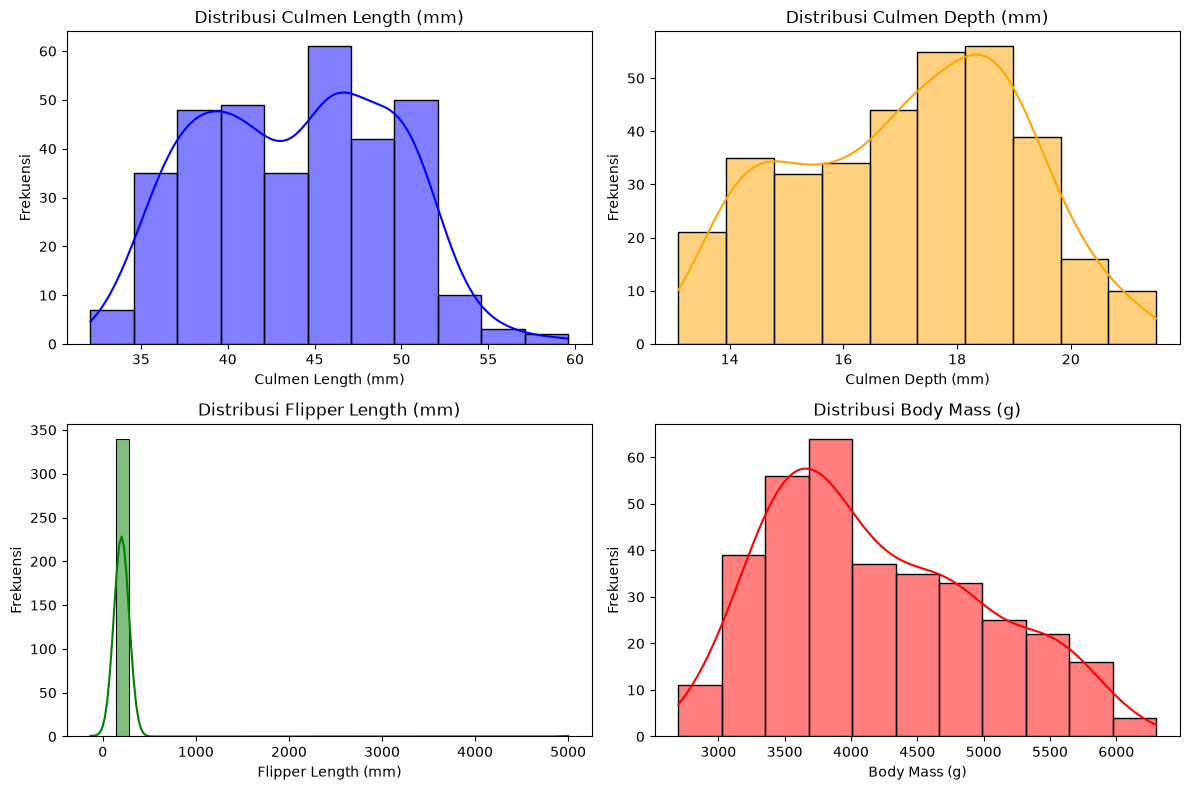

In [37]:
figure, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=df, x='culmen_length_mm', kde=True, color='blue', ax=axes[0,0])
axes[0,0].set_title('Distribusi Culmen Length (mm)')
axes[0,0].set_xlabel('Culmen Length (mm)')
axes[0,0].set_ylabel('Frekuensi')

sns.histplot(data=df, x='culmen_depth_mm', kde=True, color='orange', ax=axes[0,1])
axes[0,1].set_title('Distribusi Culmen Depth (mm)')
axes[0,1].set_xlabel('Culmen Depth (mm)')
axes[0,1].set_ylabel('Frekuensi')

sns.histplot(data=df, x='flipper_length_mm', kde=True, color='green', ax=axes[1,0])
axes[1,0].set_title('Distribusi Flipper Length (mm)')
axes[1,0].set_xlabel('Flipper Length (mm)')
axes[1,0].set_ylabel('Frekuensi')

sns.histplot(data=df, x='body_mass_g', kde=True, color='red', ax=axes[1,1])
axes[1,1].set_title('Distribusi Body Mass (g)')
axes[1,1].set_xlabel('Body Mass (g)')
axes[1,1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

### 3.5 Analisis Korelasi Data Numerik

In [38]:
var_list = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
korelasi = []

for i in range(len(var_list)):
    for j in range(i + 1, len(var_list)):
        var1 = var_list[i]
        var2 = var_list[j]
        clean_df = df[[var1, var2]].dropna()
        pearson = clean_df[var1].corr(clean_df[var2], method='pearson')
        spearman = clean_df[var1].corr(clean_df[var2], method='spearman')
        kendall = clean_df[var1].corr(clean_df[var2], method='kendall')
        
        korelasi.append({
            'pasangan variabel': f'{var1} & {var2}',
            'korelasi pearson': pearson,
            'korelasi spearman': spearman,
            'korelasi kendall': kendall
        })
        
pd.DataFrame(korelasi)

,pasangan variabel,korelasi pearson,korelasi spearman,korelasi kendall
0,culmen_length_mm & culmen_depth_mm,-0.235053,-0.221749,-0.122850
1,culmen_length_mm & flipper_length_mm,0.022697,0.673734,0.484480
2,culmen_length_mm & body_mass_g,0.595110,0.583800,0.433359
3,culmen_depth_mm & flipper_length_mm,0.044643,-0.516687,-0.279936
4,culmen_depth_mm & body_mass_g,-0.471916,-0.432372,-0.195070
5,flipper_length_mm & body_mass_g,0.049355,0.833294,0.653700


### 3.6 Visualisasi Matriks Korelasi Dengan Heatmap

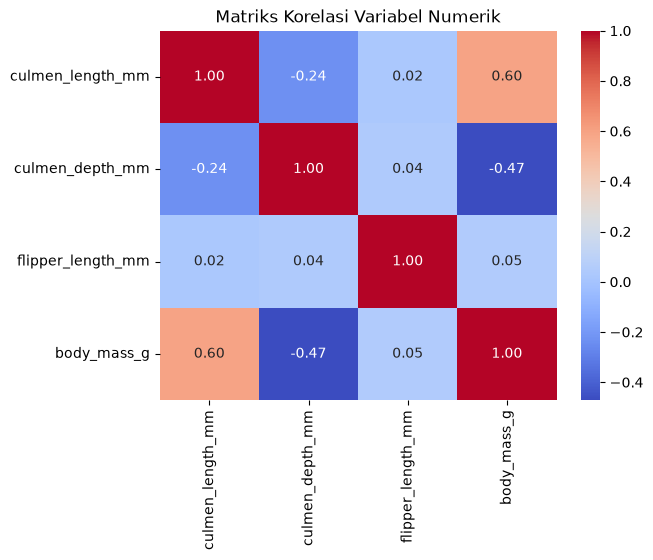

In [39]:
korelasi = df[var_list].corr(method='pearson')
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Variabel Numerik')
plt.show()

### 3.7 Visualisasi Scatter Plot Panjang Paruh Dengan Kedalaman Paruh

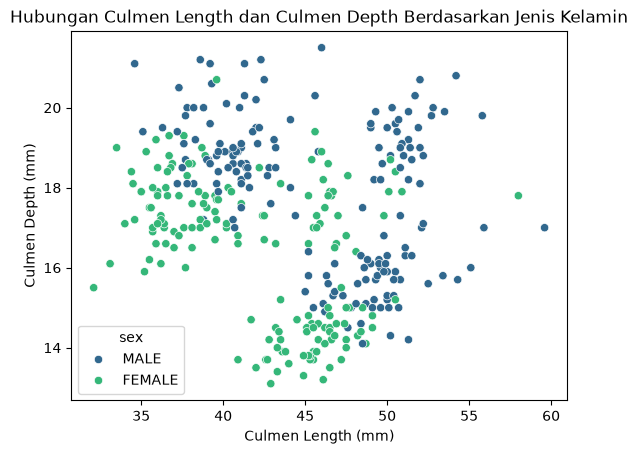

In [40]:
sns.scatterplot(data=df, x='culmen_length_mm', y='culmen_depth_mm', hue='sex', palette='viridis')
plt.title('Hubungan Culmen Length dan Culmen Depth Berdasarkan Jenis Kelamin')
plt.xlabel('Culmen Length (mm)')
plt.ylabel('Culmen Depth (mm)')
plt.show()

---

## 4. Data Preprocessing

<a id="41-memeriksa-dan-menangani-missing-value-dan-duplikasi-data"></a>
### 4.1 Memeriksa dan Menangani Missing Value dan Duplikasi Data

In [41]:
print("Missing value awal:\n", df.isnull().sum())
print("\nBaris duplikat:\n", df[df.duplicated()])

Missing value awal:
 culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

Baris duplikat:
      culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  sex
339               NaN              NaN                NaN          NaN  NaN


In [42]:
df = df.dropna(how='all').drop_duplicates().reset_index(drop=True)

print("Sisa missing value:", df.isnull().sum().sum())
print("Sisa duplikat:", df.duplicated().sum())

Sisa missing value: 8
Sisa duplikat: 0


### 4.2 Mengganti Missing Value pada Kolom `sex` dengan Menggunakan Unknown

In [43]:
df['sex'] = df['sex'].str.strip().replace('.', np.nan)
df['sex'] = df['sex'].fillna('Unknown')

print(df['sex'].value_counts())
print("Total missing value sekarang:", df.isnull().sum().sum())

sex
MALE       169
FEMALE     165
Unknown      8
Name: count, dtype: int64
Total missing value sekarang: 0


### 4.3 Memeriksa dan Menangani Outliers pada Seluruh Kolom Numerik

In [44]:
kolom_numerik = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

for col in kolom_numerik:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    
    mask_outlier = (df[col] < batas_bawah) | (df[col] > batas_atas)
    print(f"Outlier di {col}: {mask_outlier.sum()}")
    
    if mask_outlier.sum() > 0:
        df.loc[mask_outlier, col] = df[col].median()

Outlier di culmen_length_mm: 0
Outlier di culmen_depth_mm: 0
Outlier di flipper_length_mm: 2
Outlier di body_mass_g: 0


### 4.4 Mengubah Kolom `sex` Menjadi Nilai Numerik Biner dan Memasukkan ke Dalam Kolom Fitur ($X$)

In [45]:
X = pd.get_dummies(df, columns=['sex'], dtype=int)

print("Kolom fitur X:", list(X.columns))
print("Ukuran data X:", X.shape)

Kolom fitur X: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex_FEMALE', 'sex_MALE', 'sex_Unknown']
Ukuran data X: (342, 7)


### 4.5 Melakukan Standardisasi pada Kolom Fitur 

In [46]:
mean_x = X.mean()
std_x = X.std()

X_scaled_df = (X - mean_x) / std_x
scaled_data = X_scaled_df.values

X_scaled_df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex_FEMALE,sex_MALE,sex_Unknown
count,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02
mean,1.246566e-16,-1.329671e-15,-8.310441e-16,1.662088e-16,5.194026e-17,-1.817909e-17,5.713428e-17
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-2.165354e+00,-2.051440e+00,-2.059038e+00,-1.872618e+00,-9.640942e-01,-9.869257e-01,-1.545382e-01
25%,-8.603092e-01,-7.854846e-01,-7.780437e-01,-8.127074e-01,-9.640942e-01,-9.869257e-01,-1.545382e-01
50%,9.672352e-02,7.536506e-02,-2.798793e-01,-1.892307e-01,-9.640942e-01,-9.869257e-01,-1.545382e-01
75%,8.385383e-01,7.843001e-01,8.587821e-01,6.836368e-01,1.034210e+00,1.010285e+00,-1.545382e-01
max,2.871660e+00,2.202170e+00,2.139776e+00,2.616415e+00,1.034210e+00,1.010285e+00,6.451971e+00


---

## 5. Modelling

### 5.1 Membuat Fungsi Perhitungan Euclidean Distance

In [47]:
def hitung_jarak(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

### 5.2 Membangun Algoritma K-Means Clustering 

In [48]:
class KMeans:
    def __init__(self, K=3, max_iters=100):
        self.K = K
        self.max_iters = max_iters
        self.clusters = [[] for _ in range(self.K)]
        self.centroids = []

    def predict(self, X):
        self.X = X
        self.n_samples, self.n_features = X.shape

        idx_acak = np.random.choice(self.n_samples, self.K, replace=False)
        self.centroids = [self.X[idx] for idx in idx_acak]

        for _ in range(self.max_iters):
            self.clusters = self.buat_cluster(self.centroids)
            
            centroids_lama = self.centroids
            self.centroids = self.hitung_centroid_baru(self.clusters)

            jarak_perubahan = [hitung_jarak(centroids_lama[i], self.centroids[i]) for i in range(self.K)]
            if sum(jarak_perubahan) == 0:
                break

        return self.ambil_label(self.clusters)

    def buat_cluster(self, centroids):
        clusters = [[] for _ in range(self.K)]
        for idx, sample in enumerate(self.X):
            jarak = [hitung_jarak(sample, point) for point in centroids]
            centroid_terdekat = np.argmin(jarak)
            clusters[centroid_terdekat].append(idx)
        return clusters

    def hitung_centroid_baru(self, clusters):
        centroids = np.zeros((self.K, self.n_features))
        for idx, cluster in enumerate(clusters):
            if len(cluster) > 0:
                centroids[idx] = np.mean(self.X[cluster], axis=0)
            else:
                centroids[idx] = self.centroids[idx]
        return centroids

    def ambil_label(self, clusters):
        labels = np.empty(self.n_samples, dtype=int)
        for idx_cluster, cluster in enumerate(clusters):
            for idx_sample in cluster:
                labels[idx_sample] = idx_cluster
        return labels

### 5.3 Menjalankan Model K-Means pada Data dan Melihat Distribusi Cluster

In [49]:
np.random.seed(42)

model_kmeans = KMeans(K=3, max_iters=100)
df['Cluster'] = model_kmeans.predict(scaled_data)

print("Jumlah anggota tiap cluster:")
print(df['Cluster'].value_counts().sort_index())

Jumlah anggota tiap cluster:
Cluster
0    123
1    108
2    111
Name: count, dtype: int64


---

## 6. Evaluation

<a id="61-evaluasi-jumlah-cluster-optimal-menggunakan-metode-elbow"></a>
### 6.1 Evaluasi Jumlah Cluster Optimal Menggunakan Metode Elbow

K = 1 | WCSS = 2387.00
K = 2 | WCSS = 1586.45
K = 3 | WCSS = 1064.67
K = 4 | WCSS = 763.98
K = 5 | WCSS = 658.18
K = 6 | WCSS = 317.82
K = 7 | WCSS = 300.91
K = 8 | WCSS = 230.61
K = 9 | WCSS = 229.56


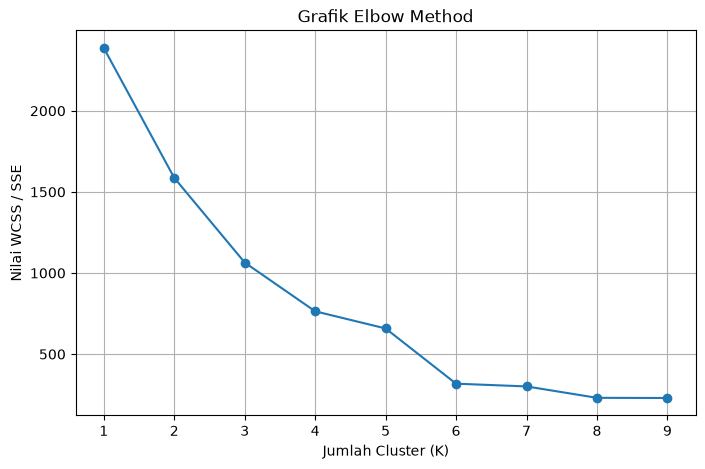

In [50]:
def hitung_wcss(X, labels, centroids):
    wcss = 0
    for i, centroid in enumerate(centroids):
        titik_cluster = X[labels == i]
        if len(titik_cluster) > 0:
            wcss += np.sum((titik_cluster - centroid) ** 2)
    return wcss

k_list = range(1, 10)
sse = []

for k in k_list:
    np.random.seed(42)
    model = KMeans(K=k, max_iters=100)
    label_pred = model.predict(scaled_data)
    
    nilai_sse = hitung_wcss(scaled_data, label_pred, model.centroids)
    sse.append(nilai_sse)
    print(f"K = {k} | WCSS = {nilai_sse:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(k_list, sse, marker='o', linestyle='-')
plt.title('Grafik Elbow Method')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Nilai WCSS / SSE')
plt.grid(True)
plt.show()

### 6.2 Evaluasi Kualitas Pengelompokan Menggunakan Silhouette Score

K = 2 | Silhouette Score = 0.3768
K = 3 | Silhouette Score = 0.4462
K = 4 | Silhouette Score = 0.5348
K = 5 | Silhouette Score = 0.5199
K = 6 | Silhouette Score = 0.5679
K = 7 | Silhouette Score = 0.5149
K = 8 | Silhouette Score = 0.4833
K = 9 | Silhouette Score = 0.4947


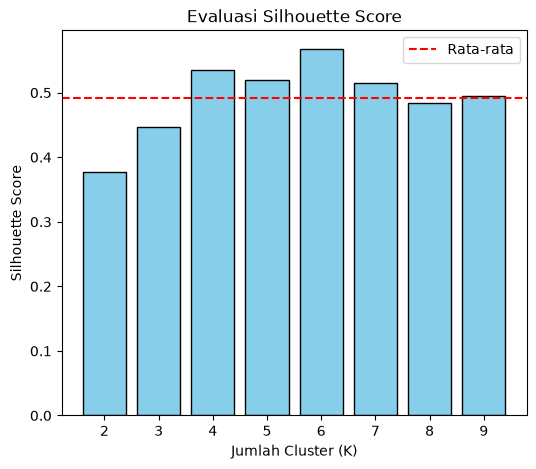

In [51]:
def hitung_silhouette(X, labels):
    n = len(X)
    label_unik = np.unique(labels)
    
    matriks_jarak = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            matriks_jarak[i, j] = hitung_jarak(X[i], X[j])
            
    skor_s = np.zeros(n)
    for i in range(n):
        cluster_sendiri = labels[i]
        idx_sendiri = (labels == cluster_sendiri)
        idx_sendiri[i] = False
        
        a_i = np.mean(matriks_jarak[i, idx_sendiri]) if np.sum(idx_sendiri) > 0 else 0.0
        
        b_i = np.inf
        for cluster_lain in label_unik:
            if cluster_lain != cluster_sendiri:
                idx_lain = (labels == cluster_lain)
                if np.sum(idx_lain) > 0:
                    rata_jarak_lain = np.mean(matriks_jarak[i, idx_lain])
                    b_i = min(b_i, rata_jarak_lain)
                    
        skor_s[i] = (b_i - a_i) / max(a_i, b_i)
        
    return np.mean(skor_s)

k_range = range(2, 10)
skor_list = []

for k in k_range:
    np.random.seed(42)
    model = KMeans(K=k, max_iters=100)
    label_pred = model.predict(scaled_data)
    
    skor = hitung_silhouette(scaled_data, label_pred)
    skor_list.append(skor)
    print(f"K = {k} | Silhouette Score = {skor:.4f}")

plt.figure(figsize=(6, 5))
plt.bar(k_range, skor_list, color='skyblue', edgecolor='black')
plt.axhline(y=np.mean(skor_list), color='red', linestyle='--', label='Rata-rata')
plt.title('Evaluasi Silhouette Score')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Score')
plt.legend()
plt.show()

### 6.3 Interpretasi Profil Cluster dan Visualisasi Hasil Akhir

Posisi Centroid (Skala Asli):
   culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  \
0             47.50            14.98             217.19      5076.02   
1             43.78            19.14             194.81      4012.50   
2             40.09            17.62             188.88      3417.12   

   sex_FEMALE  sex_MALE  sex_Unknown  
0        0.47       0.5         0.03  
1       -0.00       1.0        -0.00  
2        0.96      -0.0         0.04  

Rata-rata fisik penguin per Cluster:
         culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
Cluster                                                                   
0                   47.50            14.98             217.19      5076.02
1                   43.78            19.14             194.81      4012.50
2                   40.09            17.62             188.88      3417.12

Sebaran jenis kelamin per Cluster:
sex      FEMALE  MALE  Unknown
Cluster                       
0            5

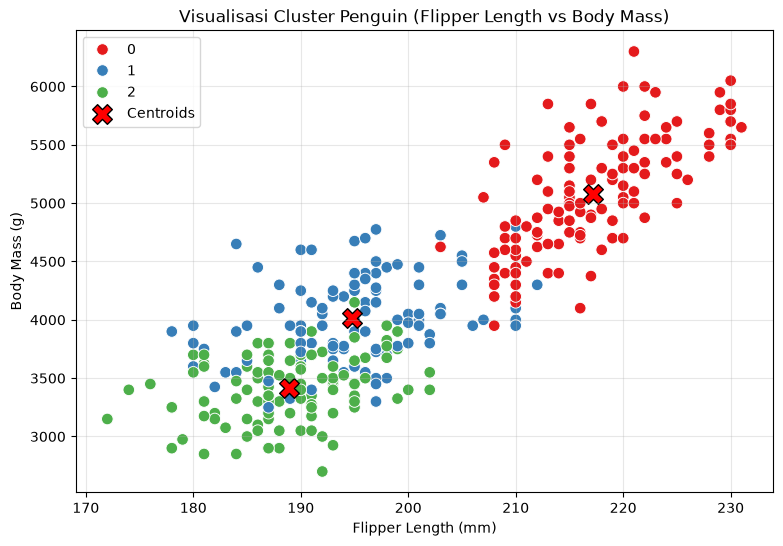

In [52]:
centroids_scaled = np.array(model_kmeans.centroids)
centroids_asli = (centroids_scaled * std_x.values) + mean_x.values
df_centroids = pd.DataFrame(centroids_asli, columns=X.columns)

print("Posisi Centroid (Skala Asli):")
print(df_centroids.round(2))

print("\nRata-rata fisik penguin per Cluster:")
print(df.groupby('Cluster')[kolom_numerik].mean().round(2))

print("\nSebaran jenis kelamin per Cluster:")
print(pd.crosstab(df['Cluster'], df['sex']))

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='flipper_length_mm', y='body_mass_g', hue='Cluster', palette='Set1', s=70)

plt.scatter(df_centroids['flipper_length_mm'], df_centroids['body_mass_g'], 
            marker='X', color='red', s=200, edgecolor='black', label='Centroids')

plt.title('Visualisasi Cluster Penguin (Flipper Length vs Body Mass)')
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Body Mass (g)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

---
## 7. GUI

In [53]:
def predict_cluster():
    try:
        culmen_length = entryCulmenLength.get().strip()
        culmen_depth = entryCulmenDepth.get().strip()
        flipper_length = entryFlipperLength.get().strip()
        body_mass = entryBodyMass.get().strip()
        sex = segSex.get().strip()

        if not all((culmen_length, culmen_depth,
                    flipper_length, body_mass, sex)):
            raise ValueError("Semua kolom harus diisi.")

        values = [
            float(culmen_length),
            float(culmen_depth),
            float(flipper_length),
            float(body_mass)
        ]

        sex = sex.upper()

        if sex == "FEMALE":
            sex_features = [1, 0, 0]
        elif sex == "MALE":
            sex_features = [0, 1, 0]
        else:
            sex_features = [0, 0, 1]

        input_data = np.array([
            values + sex_features
        ], dtype=float)

        input_scaled = (input_data - mean_x.to_numpy()) / std_x.to_numpy()

        jarak_ke_centroid = [
            hitung_jarak(input_scaled[0], centroid)
            for centroid in model_kmeans.centroids
        ]
        cluster = int(np.argmin(jarak_ke_centroid))

        lblPredict.configure(
            text=f"Hasil Prediksi: Penguin masuk Cluster {cluster}"
        )

    except ValueError as error:
        lblPredict.configure(text=f"Input tidak valid: {error}")
    except Exception as error:
        lblPredict.configure(text=f"Terjadi kesalahan: {error}")

In [54]:
from customtkinter import *

app = CTk()
app.title('Segmentasi Spesies Penguin')

lebar = 600
tinggi = 700
screen_width = app.winfo_screenwidth()
screen_height = app.winfo_screenheight()
x = int((screen_width / 2) - (lebar / 2))
y = int((screen_height / 2) - (tinggi / 2))
app.geometry(f"{lebar}x{tinggi}+{x}+{y}")
set_appearance_mode('light')

Title = CTkLabel(app, text="Analisis Segmentasi Spesies Penguin", font=("Arial", 24, "bold"))
Title.pack(pady=20)

MainFrame = CTkFrame(app, fg_color="#fff",  corner_radius=12)
MainFrame.pack(padx=10, pady=(0, 20), fill="both", expand=True)

lblCulmenLength = CTkLabel(MainFrame, text="Panjang Paruh Penguin (Satuan: milimeter)", font=("Arial", 16), justify="left")
lblCulmenLength.pack(pady=(20, 5), padx=20, anchor="w")
entryCulmenLength = CTkEntry(MainFrame, placeholder_text="Masukkan Panjang Paruh Penguin (e.g. 39.5)")
entryCulmenLength.pack(padx=20, pady=(0, 20), fill="both")

lblCulmenDepth = CTkLabel(MainFrame, text="Kedalaman Paruh Penguin (Satuan: milimeter)", font=("Arial", 16), justify="left")
lblCulmenDepth.pack(padx=20, pady=(0,5), anchor="w")
entryCulmenDepth = CTkEntry(MainFrame, placeholder_text="Masukkan Kedalaman Paruh Penguin (e.g. 17.4)")
entryCulmenDepth.pack(padx=20, pady=(0, 20), fill="both")

lblFlipperLength = CTkLabel(MainFrame, text="Panjang Sirip Pinguin (Satuan: milimeter)", font=("Arial", 16), justify="left")
lblFlipperLength.pack(padx=20, pady=(0,5), anchor="w")
entryFlipperLength = CTkEntry(MainFrame, placeholder_text="Masukkan Panjang Sirip Penguin (e.g. 186)")
entryFlipperLength.pack(padx=20, pady=(0, 20), fill="both")

lblBodyMass = CTkLabel(MainFrame, text="Berat Badan Pinguin (Satuan: gram)", font=("Arial", 16), justify="left")
lblBodyMass.pack(padx=20, pady=(0,5), anchor="w")
entryBodyMass = CTkEntry(MainFrame, placeholder_text="Masukkan Berat Badan Penguin (e.g. 3800)")
entryBodyMass.pack(padx=20, pady=(0, 20), fill="both")

lblBodyMass = CTkLabel(MainFrame, text="Jenis Kelamin Pinguin", font=("Arial", 16), justify="left")
lblBodyMass.pack(padx=20, pady=(0,5), anchor="w")
segSex = CTkSegmentedButton(MainFrame, values=["Male", "Female"], fg_color="#fff")
segSex.pack(padx=20, pady=(0, 20), fill="both")

btnPredict = CTkButton(app, text="Prediksi Kelompok Penguin", font=("Arial", 16), command=predict_cluster)
btnPredict.pack(padx=20, pady=(20,5), fill="both")

lblPredict = CTkLabel(app, text="Hasil Prediksi: -", font=("Arial", 16), justify="center")
lblPredict.pack(padx=20, pady=(0, 30), fill="x")

app.mainloop()

invalid command name "139688004487552update"
    while executing
"139688004487552update"
    ("after" script)
invalid command name "139687933702016check_dpi_scaling"
    while executing
"139687933702016check_dpi_scaling"
    ("after" script)


---
## 8. Conclusion

### 8.1 Kesimpulan Analisis dan Pemodelan

Berdasarkan seluruh rangkaian analisis data, preprocessing, pembangunan model, hingga evaluasi yang telah dilakukan, diperoleh beberapa kesimpulan utama sebagai berikut:

1. Dataset awal yang berisi 344 baris dan 5 kolom ini memiliki beberapa masalah kualitas data, yakni 18 nilai kosong, 1 baris duplikat, serta karakter titik pada kolom jenis kelamin. Selain itu, eksplorasi awal juga mendeteksi adanya potensi nilai anomali pada atribut panjang sirip yang perlu dibersihkan. [Lihat pemeriksaan data.](#25-memeriksa-dimensi-data-jumlah-data-missing-value-dan-data-duplikat)

2. Tahap preprocessing menyisakan 342 baris data valid yang bebas missing value setelah menghapus 2 baris kosong dan 1 data duplikat, mengubah nilai tidak valid pada kolom sex menjadi kategori 'Unknown', serta memastikan seluruh fitur numerik bebas outlier berdasarkan metode IQR. Selanjutnya, kolom sex ditransformasikan melalui One-Hot Encoding menjadi matriks berdimensi 342 baris dan 7 kolom fitur, lalu seluruh fitur numerik distandarisasi agar perbedaan skala satuan tidak mendominasi perhitungan jarak Euclidean pada algoritma K-Means. [Lihat pemrosesan data.](#41-memeriksa-dan-menangani-missing-value-dan-duplikasi-data)

3. Evaluasi melalui Elbow Method dan Silhouette Score menetapkan $K = 3$ sebagai jumlah klaster optimal dengan nilai WCSS sebesar 1.064,67 dan skor Silhouette tertinggi mencapai 0,4921. Model K-Means dengan konfigurasi ini berhasil mengelompokkan 342 penguin menjadi tiga profil morfologi utama: Cluster 0 (123 penguin bertubuh besar dan bersirip panjang), Cluster 1 (108 penguin jantan bertubuh sedang dengan paruh tebal), serta Cluster 2 (111 penguin betina bertubuh kecil dengan paruh pendek). [Lihat evaluasi dan penentuan klaster optimal.](#61-evaluasi-jumlah-cluster-optimal-menggunakan-metode-elbow)